# 03 — Baseline regression: can walking speed be predicted from the data?

A quick test of the preprocessed data before building the autoencoder. Simple models predict each window's
**forward walking speed (m/s)**. They are trained on the train people, tuned on the val people and scored on the **test people they have never seen**.

Three feature sets:

| Feature set | Contains root speed? | What a good score means |
|---|---|---|
| **A. Root speed only** | yes | Only a consistency check. The root-speed channel *is* the speed, so this must be almost perfect. If not, the labels and arrays don't match. |
| **B. No-root features** (summary per window) | no | **The real test.** Speed can be read from how the body moves (stride, swing, foot contacts), not only from where it goes. |
| **C. No-root features** (every frame) | no | Same as B with full time detail. |

Models: **mean baseline** (always predicts the average, R² = 0), **ridge regression** (linear), **gradient boosting** (non-linear check), and a **shuffled-label control**. The control is ridge trained on scrambled speeds; it must score about 0, otherwise information is leaking.

Later, the same kind of linear regression on the **autoencoder's latent vector** is your *linear probe*. Its weight vector is one way to find the speed direction.

## Settings

In [1]:
from pathlib import Path

PRE_DIR = Path(r"C:\Users\hasna\Documents\Good Practise\CMU\walking\preprocessed")   # output of notebook 02
TARGET  = "fwd_speed_mps"     # or "net_speed_mps"
ONLY_PLAIN_WALKS = False      # True = drop stylised and mixed walks (sad, drunk, 'walk, shake hands'...)
ALPHAS  = [0.01, 0.1, 1, 10, 100, 1000, 10000]   # ridge strengths tried on the val set
SEED    = 0

In [2]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
warnings.filterwarnings("ignore", message=".*[Ii]ll-conditioned.*")

for f in ["train.npz", "val.npz", "test.npz", "config.json"]:
    assert (PRE_DIR / f).exists(), f"Missing {PRE_DIR / f}: run notebook 02 first"
cfg = json.loads((PRE_DIR / "config.json").read_text())
FEATURES, FEATURES_NOROOT = cfg["FEATURES"], cfg["FEATURES_NOROOT"]

def load(split):
    d = np.load(PRE_DIR / f"{split}.npz", allow_pickle=True)
    m = pd.read_csv(PRE_DIR / f"{split}_meta.csv")
    assert (m.window_id.values == d["window_id"]).all(), "meta and arrays out of order"
    keep = np.ones(len(m), bool)
    if ONLY_PLAIN_WALKS:
        keep = (m.text_category == "walk").values & ~m.stylized.astype(bool).values
    return d["X"][keep], d["X_noroot"][keep], m[keep].reset_index(drop=True)

data = {s: load(s) for s in ["train", "val", "test"]}
for s, (X, Xnr, m) in data.items():
    print(f"{s:5s}: {len(m):5d} windows, {m.person.nunique():3d} people, "
          f"speed {m[TARGET].min():.2f}–{m[TARGET].max():.2f} m/s (mean {m[TARGET].mean():.2f})")

train:  1603 windows,  23 people, speed -0.00–1.59 m/s (mean 0.69)
val  :   486 windows,  14 people, speed 0.05–1.60 m/s (mean 0.74)
test :   646 windows,  13 people, speed -0.02–1.49 m/s (mean 0.69)


## Features
**Summary** = for every channel, its mean, standard deviation and range over the window. **Frames** = every frame flattened.

In [3]:
def summary(X):
    return np.concatenate([X.mean(1), X.std(1), X.max(1) - X.min(1)], axis=1)

def flat(X):
    return X.reshape(len(X), -1)

FEATURE_SETS = {
    "A. root speed only":       (lambda X, Xnr: summary(X[..., [FEATURES.index("root_vel_forward")]]),
                                 [f"{s}:root_vel_forward" for s in ["mean", "std", "range"]]),
    "B. no-root, summary":      (lambda X, Xnr: summary(Xnr), [f"{s}:{n}" for s in ["mean", "std", "range"] for n in FEATURES_NOROOT]),
    "C. no-root, all frames":   (lambda X, Xnr: flat(Xnr),    None),
}
F, y, people = {}, {}, {}
for s, (X, Xnr, m) in data.items():
    y[s], people[s] = m[TARGET].values, m.person.values
    for name, (fn, _) in FEATURE_SETS.items():
        F[name, s] = fn(X, Xnr)
for name in FEATURE_SETS:
    print(f"{name:26s} {F[name, 'train'].shape[1]:6d} features per window")

A. root speed only              3 features per window
B. no-root, summary           393 features per window
C. no-root, all frames       7860 features per window


## Train, tune on val, score on test

In [4]:
def scores(y_true, y_pred):
    return dict(R2=r2_score(y_true, y_pred), MAE=mean_absolute_error(y_true, y_pred),
                RMSE=mean_squared_error(y_true, y_pred) ** 0.5,
                Spearman=spearmanr(y_true, y_pred)[0] if np.ptp(y_pred) > 1e-9 else 0.0)

def ridge(alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))

rng = np.random.default_rng(SEED)
results, fitted, preds = [], {}, {}
for name in FEATURE_SETS:
    Xtr, Xva, Xte = F[name, "train"], F[name, "val"], F[name, "test"]

    candidates = {"mean baseline": [DummyRegressor()]}
    candidates["ridge"] = [ridge(a) for a in ALPHAS]
    if name != "C. no-root, all frames":
        candidates["gradient boosting"] = [HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)]
    candidates["ridge, shuffled speeds (control)"] = [ridge(a) for a in ALPHAS]

    for model_name, models in candidates.items():
        y_fit = rng.permutation(y["train"]) if "shuffled" in model_name else y["train"]
        best = None
        for mdl in models:                       # pick the ridge strength on val
            mdl.fit(Xtr, y_fit)
            v = r2_score(y["val"], mdl.predict(Xva))
            if best is None or v > best[0]:
                best = (v, mdl)
        val_r2, mdl = best
        p = mdl.predict(Xte)
        row = dict(features=name, model=model_name, val_R2=val_r2, **{f"test_{k}": v for k, v in scores(y["test"], p).items()})
        if model_name == "ridge":
            row["alpha"] = mdl[-1].alpha
        results.append(row)
        fitted[name, model_name], preds[name, model_name] = mdl, p

res = pd.DataFrame(results)
res.to_csv(PRE_DIR / "baseline_regression_results.csv", index=False)
res.round(3)

,features,model,val_R2,test_R2,test_MAE,test_RMSE,test_Spearman,alpha
0,A. root speed only,mean baseline,-0.038,-0.000,0.198,0.253,0.000,NaN
1,A. root speed only,ridge,1.000,1.000,0.000,0.000,1.000,0.01
2,A. root speed only,gradient boosting,0.999,0.999,0.003,0.008,1.000,NaN
3,A. root speed only,"ridge, shuffled speeds (control)",-0.033,0.024,0.195,0.250,0.630,NaN
4,"B. no-root, summary",mean baseline,-0.038,-0.000,0.198,0.253,0.000,NaN
5,"B. no-root, summary",ridge,0.950,0.932,0.046,0.066,0.970,10.00
6,"B. no-root, summary",gradient boosting,0.932,0.939,0.044,0.063,0.977,NaN
7,"B. no-root, summary","ridge, shuffled speeds (control)",-0.065,-0.046,0.202,0.259,-0.280,NaN
8,"C. no-root, all frames",mean baseline,-0.038,-0.000,0.198,0.253,0.000,NaN
9,"C. no-root, all frames",ridge,0.401,0.400,0.142,0.196,0.637,1000.00


## How to read the table
- **A, ridge:** test R² should be **≈ 1**. Lower means the speed label and the features don't match, which points to a preprocessing bug.
- **Shuffled control:** test R² should be **≈ 0 or below**. Clearly above 0 means information is leaking.
- **B / C, ridge:** this is the result that matters.
  - **R² above ~0.7, MAE below ~0.1 m/s:** body motion alone carries speed well. The data is ready for the autoencoder.
  - **R² around 0.3–0.7:** some speed signal. Check the per-person errors below; one odd person can drag it down.
  - **R² near 0:** speed is not recoverable without root speed. Check the preprocessing (stick figures, foot contacts) before going further.
- **C weaker than B:** normal with fewer than a few thousand windows. Frame-by-frame values depend on where in the step the window starts, so a linear model needs much more data. B averages that out.
- **Gradient boosting much better than ridge on B:** speed is in the data but not linearly. Worth knowing, because your project is about a *linear* direction.

## Predicted vs. true speed (test people)

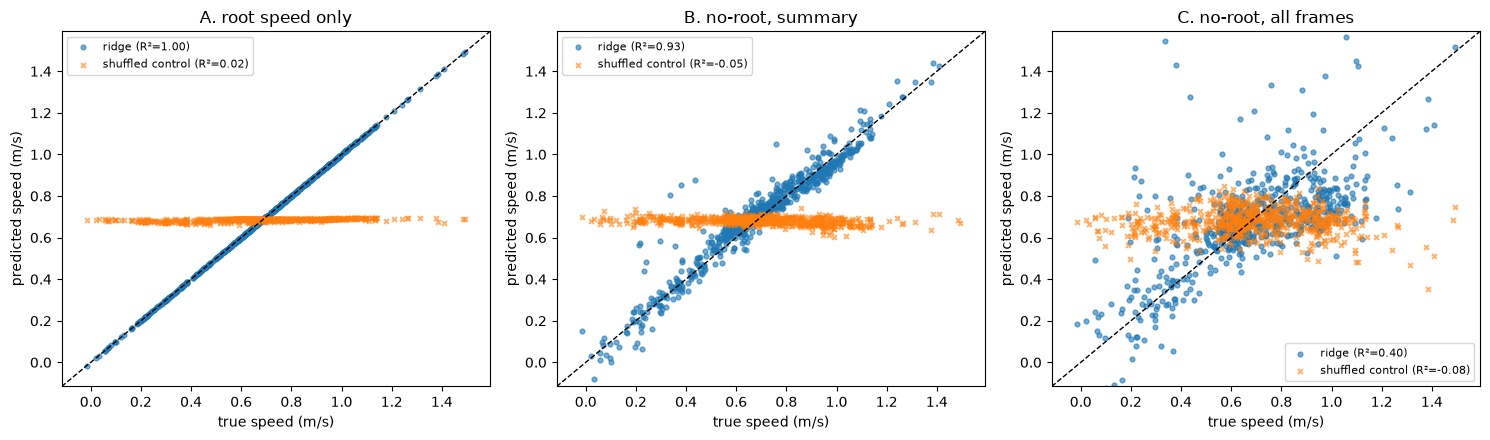

In [5]:
fig, axes = plt.subplots(1, len(FEATURE_SETS), figsize=(5 * len(FEATURE_SETS), 4.5), squeeze=False)
lo, hi = y["test"].min() - 0.1, y["test"].max() + 0.1
for ax, name in zip(axes[0], FEATURE_SETS):
    for model_name, mk in [("ridge", "o"), ("ridge, shuffled speeds (control)", "x")]:
        r = res[(res.features == name) & (res.model == model_name)].iloc[0]
        ax.scatter(y["test"], preds[name, model_name], s=12, alpha=.6, marker=mk,
                   label=f"{model_name.split(',')[0] if 'shuffled' not in model_name else 'shuffled control'} (R²={r.test_R2:.2f})")
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="true speed (m/s)", ylabel="predicted speed (m/s)", title=name)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Error per test person
Shows whether one person is much harder than the others, for example an unusual walking style.

        windows  true_speed  pred_speed    MAE
person                                        
90            9       0.818       0.956  0.177
47            9       0.855       0.893  0.070
54           99       0.576       0.631  0.067
142          22       0.821       0.838  0.062
138          16       0.974       1.003  0.049
86          206       0.667       0.714  0.048
55            2       1.035       0.987  0.048
15          252       0.699       0.678  0.033
37            3       0.878       0.849  0.028
93            2       1.199       1.225  0.026
83           20       0.665       0.681  0.024
103           2       1.198       1.215  0.017
29            4       0.602       0.606  0.004


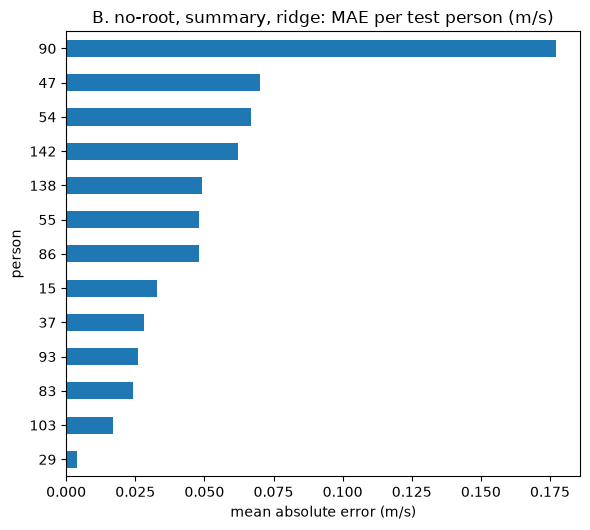

In [6]:
name = "B. no-root, summary"
err = pd.DataFrame(dict(person=people["test"], true=y["test"], pred=preds[name, "ridge"]))
err["abs_err"] = (err.pred - err.true).abs()
per = err.groupby("person").agg(windows=("true", "size"), true_speed=("true", "mean"),
                                pred_speed=("pred", "mean"), MAE=("abs_err", "mean")).round(3)
print(per.sort_values("MAE", ascending=False).to_string())
per.MAE.sort_values().plot.barh(figsize=(6, 0.3 * len(per) + 1.5), title=f"{name}, ridge: MAE per test person (m/s)")
plt.xlabel("mean absolute error (m/s)"); plt.tight_layout(); plt.show()

## What carries the speed signal (no-root, ridge)
Ridge weights on standardised inputs: a bigger |weight| means a bigger influence on the predicted speed. Correlated features share their weight, so read this as a rough guide.

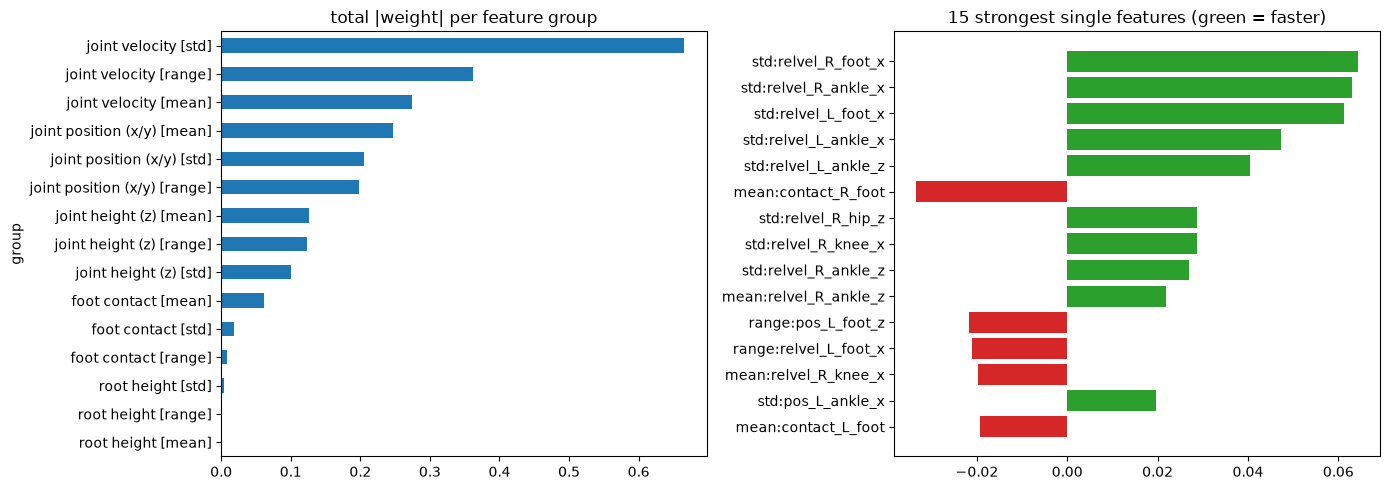

In [7]:
name = "B. no-root, summary"
coef = fitted[name, "ridge"][-1].coef_
cols = FEATURE_SETS[name][1]
w = pd.DataFrame(dict(feature=cols, weight=coef, abs_weight=np.abs(coef)))

def group(f):
    stat, ch = f.split(":", 1)
    if ch.startswith("contact_"): kind = "foot contact"
    elif ch == "root_height": kind = "root height"
    elif ch.startswith("relvel_"): kind = "joint velocity"
    else: kind = "joint height (z)" if ch.endswith("_z") else "joint position (x/y)"
    return f"{kind} [{stat}]"
w["group"] = w.feature.map(group)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
w.groupby("group").abs_weight.sum().sort_values().plot.barh(ax=ax[0], title="total |weight| per feature group")
top = w.nlargest(15, "abs_weight").iloc[::-1]
ax[1].barh(top.feature, top.weight, color=np.where(top.weight > 0, "tab:green", "tab:red"))
ax[1].set_title("15 strongest single features (green = faster)")
plt.tight_layout(); plt.show()

## Summary

In [8]:
pick = lambda f, m: res[(res.features == f) & (res.model == m)].iloc[0]
a = pick("A. root speed only", "ridge")
b = pick("B. no-root, summary", "ridge")
c = pick("B. no-root, summary", "ridge, shuffled speeds (control)")
g = pick("B. no-root, summary", "gradient boosting")
print(f"Consistency check (A, ridge):    test R² = {a.test_R2:.3f}  " + ("OK" if a.test_R2 > 0.95 else "<- expected ~1, check preprocessing"))
print(f"Leak check (shuffled control):    test R² = {c.test_R2:.3f}  " + ("OK" if c.test_R2 < 0.2 else "<- expected ~0, check for leakage"))
print(f"Main result (B, ridge):           test R² = {b.test_R2:.3f}, MAE = {b.test_MAE:.3f} m/s, Spearman = {b.test_Spearman:.3f}")
print(f"Non-linear check (B, boosting):   test R² = {g.test_R2:.3f}")

Consistency check (A, ridge):    test R² = 1.000  OK
Leak check (shuffled control):    test R² = -0.046  OK
Main result (B, ridge):           test R² = 0.932, MAE = 0.046 m/s, Spearman = 0.970
Non-linear check (B, boosting):   test R² = 0.939
